## Question:
In a game of skiing, what is the probability that an AI agent moving randomly beats a level in ten seconds or less

The random variable is time; the values it can be are ten seconds or less

In [1]:
!pip install gymnasium
!pip install "gymnasium[atari]"
!pip install ale-py
!pip install autorom[accept-rom-license]

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   -------------------- ------------------- 1/2 [gymnasium]
   ---------------------------------------- 2/2 [gymnasium]

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 20.4 MB/s  0:00:00
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
  I

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

ModuleNotFoundError: No module named 'ale_py'

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [ ]:
# Create environment
env = gym.make('ALE/Skiing-v5', render_mode='rgb_array')
observation, info = env.reset()

In [ ]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

In [ ]:
# Play game randomly
total_reward = 0

for step in range(500):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value)
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()

In [ ]:
import time
import ale_py
import gymnasium as gym

In [ ]:
# Register ALE environments
gym.register_envs(ale_py)

In [ ]:
env = gym.make("ALE/Skiing-v5")

In [ ]:
num_games = 100
game_times = []
wins_within_10s = 0

In [ ]:
for game in range(num_games):
    observation, info = env.reset()
    start_time = time.time()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        elapsed_time = time.time() - start_time

        # End episode after 10 seconds
        if elapsed_time >= 10.0:
            break

        # Select a random action
        action = env.action_space.sample()
        observation, reward, terminated, truncated, info = env.step(action)

    final_time = time.time() - start_time
    game_times.append(final_time)

    # In Atari Skiing, terminated indicates reaching the finish line
    if terminated and final_time <= 10.0:
        wins_within_10s += 1

env.close()

In [ ]:
# Results
probability = wins_within_10s / num_games

In [ ]:
print(f"Simulated {num_games} games.")
print(f"Games beat in <= 10s: {wins_within_10s}")
print(f"Estimated Probability: {probability:.4f}")

In [ ]:
# Calculate mean and standard deviation from your recorded game_times
mean_time = np.mean(game_times)
std_time = np.std(game_times)

In [ ]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate mean and standard deviation from your recorded game_times
mean_time = np.mean(game_times)
std_time = np.std(game_times)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot a histogram of the game times
ax.hist(game_times, bins=30, color='skyblue', edgecolor='black', alpha=0.7, label='Game Times')

# Add a vertical line for the Mean
ax.axvline(mean_time, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_time:.2f}s')

# Add vertical lines and shading for +/- 1 Standard Deviation
ax.axvline(mean_time - std_time, color='orange', linestyle=':', linewidth=2, label=f'-1 Std Dev: {mean_time - std_time:.2f}s')
ax.axvline(mean_time + std_time, color='orange', linestyle=':', linewidth=2, label=f'+1 Std Dev: {mean_time + std_time:.2f}s')
ax.axvspan(mean_time - std_time, mean_time + std_time, color='orange', alpha=0.15, label='±1 Std Dev Range')

# Formatting and labels
ax.set_title('Distribution of AI Agent Game Times in ALE/Skiing-v5', fontsize=14)
ax.set_xlabel('Time (seconds)', fontsize=12)
ax.set_ylabel('Frequency (Number of Games)', fontsize=12)
ax.legend()
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

## Conclusion:

Assuming this is our normal distribution an agent on average needs around .49 seconds to beat skiing

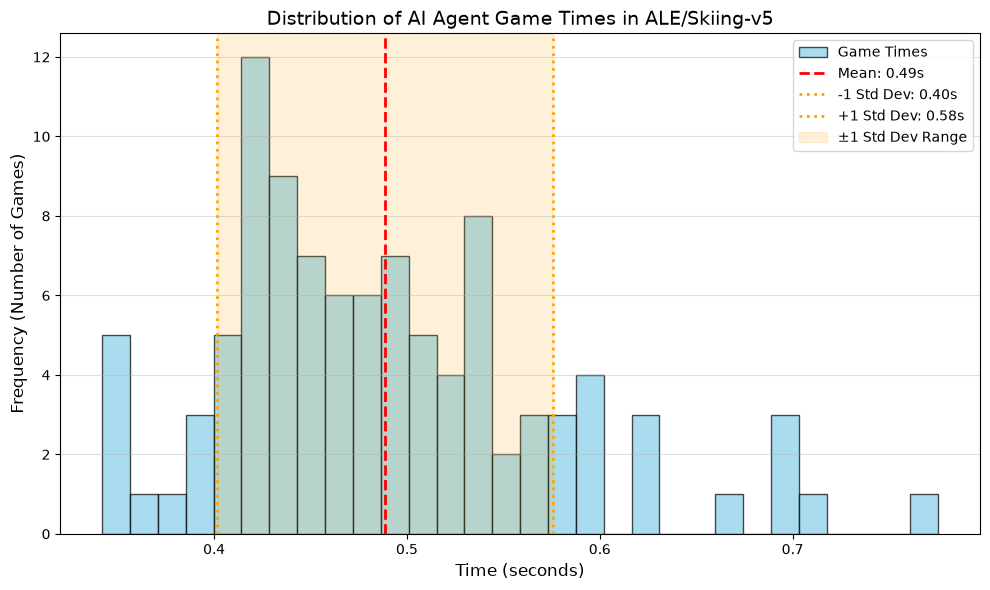